# Morfologia II: abertura e fechamento

In [1]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


In [2]:
import cv2

from src.preprocessamento import para_cinza
from src.segmentacao import segmentar_otsu, sobrepor
from src.morfologia import erosao, dilatacao, abertura, fechamento, limpar_mascara

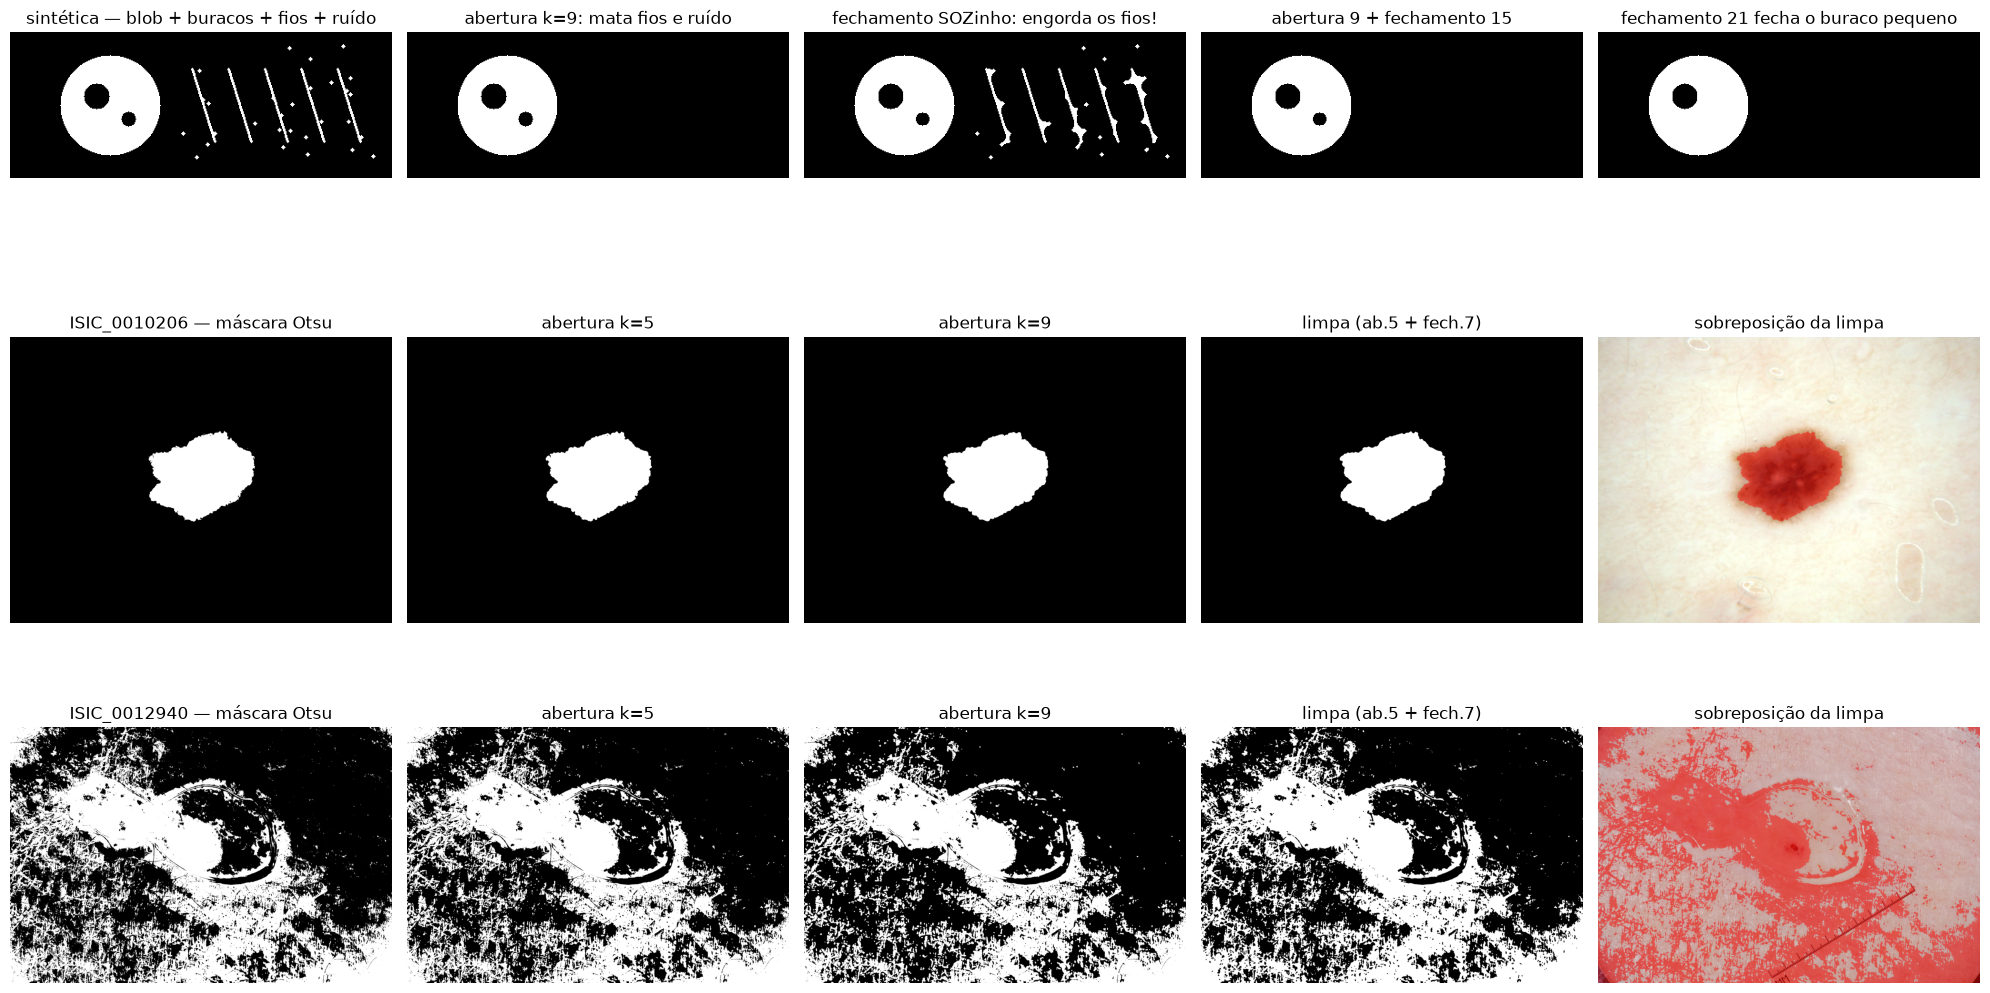

In [5]:
# linha 1: sintética com TODOS os problemas de uma vez (buracos + fios + ruído)
sintetica = np.zeros((160, 420), dtype=np.uint8)
cv2.circle(sintetica, (110, 80), 55, 255, -1)          # blob grande
cv2.circle(sintetica, (95, 70), 14, 0, -1)             # buraco interno
cv2.circle(sintetica, (130, 95), 8, 0, -1)             # segundo buraco
for x in range(200, 400, 40):
    cv2.line(sintetica, (x, 40), (x + 25, 120), 255, 2)   # fios finos
for _ in range(30):
    x, y = np.random.randint(190, 410), np.random.randint(10, 150)
    cv2.circle(sintetica, (int(x), int(y)), 2, 255, -1)   # salpicados

fig, axes = plt.subplots(3, 5, figsize=(20, 12))

painel_sintetico = [
    (sintetica, "sintética — blob + buracos + fios + ruído"),
    (abertura(sintetica, 9), "abertura k=9: mata fios e ruído"),
    (fechamento(sintetica, 15), "fechamento SOZinho: engorda os fios!"),
    (limpar_mascara(sintetica, 9, 15), "abertura 9 + fechamento 15"),
    (limpar_mascara(sintetica, 9, 21), "fechamento 21 fecha o buraco pequeno"),
]
for j, (img, tit) in enumerate(painel_sintetico):
    axes[0, j].imshow(img, cmap="gray")
    axes[0, j].set_title(tit)
    axes[0, j].axis("off")

for i, nome in enumerate(["ISIC_0010206.jpg", "ISIC_0012940.jpg"], start=1):
    img = carregar_imagem(PASTA_IMAGENS / nome)
    cinza = para_cinza(img)
    msk = segmentar_otsu(cinza)
    nome_curto = Path(nome).stem
    limpa = limpar_mascara(msk, 5, 7)
    painel = [
        (msk, f"{nome_curto} — máscara Otsu"),
        (abertura(msk, 5), "abertura k=5"),
        (abertura(msk, 9), "abertura k=9"),
        (limpa, "limpa (ab.5 + fech.7)"),
        (sobrepor(img, limpa), "sobreposição da limpa"),
    ]
    for j, (p_img, tit) in enumerate(painel):
        axes[i, j].imshow(p_img if p_img.ndim == 3 else p_img, cmap=None if p_img.ndim == 3 else "gray")
        axes[i, j].set_title(tit)
        axes[i, j].axis("off")

fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "morfologia" / "abertura_fechamento.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)